# NLP Sentiment Classification on Movie Reviews (TF-IDF)

**Goal:** Classify reviews as **positive** or **negative** using TF-IDF features with Multinomial Naive Bayes and Logistic Regression, then test the model on live custom phrases.

**Pipeline**
1. Load 2,000 labelled movie reviews
2. Clean and tokenize text: lowercase, strip HTML and punctuation, remove stopwords, lemmatize
3. Convert text to numbers with `TfidfVectorizer(max_features=5000)`
4. Train `MultinomialNB` and `LogisticRegression`, tuned with cross-validation
5. Benchmark accuracy, precision, recall, F1; plot confusion matrices
6. `predict_sentiment()` function for live custom input

## 1. Imports and setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score)

# One-off downloads of the NLTK word lists (needs internet the first time only)
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

## 2. Load the dataset

In [2]:
df = pd.read_csv("movie_reviews.csv")   # keep the CSV in the same folder as this notebook
df["label"] = (df["sentiment"] == "pos").astype(int)   # 1 = positive, 0 = negative

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum(), "| Duplicate reviews:", df["review"].duplicated().sum())
print(df["sentiment"].value_counts())
df.head(3)

Shape: (2000, 3)
Missing values: 0 | Duplicate reviews: 0
sentiment
pos    1000
neg    1000
Name: count, dtype: int64


,review,sentiment,label
0,the verdict : spine-chilling drama from horror...,pos,1
1,""" the 44 caliber killer has struck again . "" ...",neg,0
2,in the company of men made a splash at the sun...,pos,1


**Dataset:** the NLTK Movie Reviews corpus (Pang & Lee), with 1,000 positive and 1,000 negative full-length reviews. The classes are perfectly balanced, so accuracy is a fair metric here.

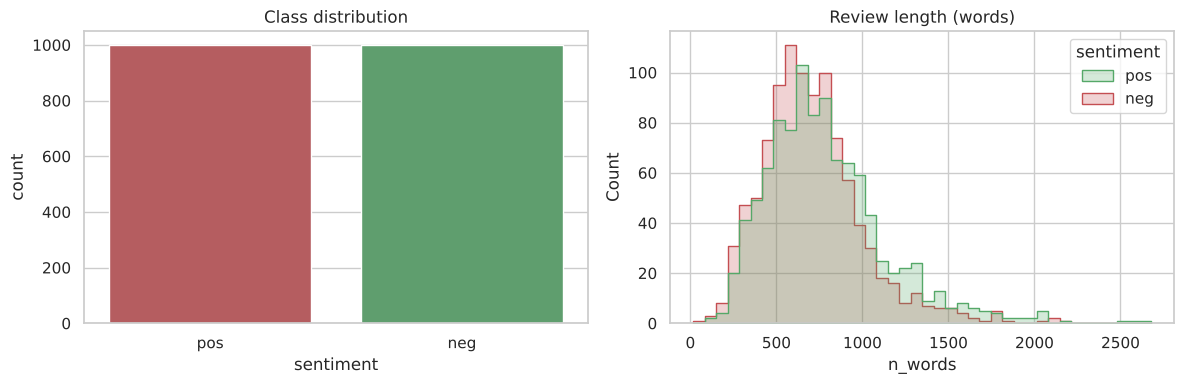

            count   mean    std    min    25%    50%    75%     max
sentiment                                                          
neg        1000.0  706.0  297.0   17.0  510.0  668.0  848.0  2181.0
pos        1000.0  787.0  353.0  130.0  544.0  732.0  957.0  2678.0


In [3]:
df["n_words"] = df["review"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="sentiment", data=df, hue="sentiment", palette=["#c44e52", "#55a868"], legend=False, ax=axes[0])
axes[0].set_title("Class distribution")
sns.histplot(data=df, x="n_words", hue="sentiment", bins=40, element="step",
             palette={"neg": "#c44e52", "pos": "#55a868"}, ax=axes[1])
axes[1].set_title("Review length (words)")
plt.tight_layout(); plt.show()
print(df.groupby("sentiment")["n_words"].describe().round(0))

## 3. Text preprocessing

Steps, in order:
1. **Lowercase** everything
2. Remove **HTML tags**
3. Remove **punctuation, digits and special characters** (keep letters only)
4. **Tokenize** into words
5. Remove **stopwords** (but keep negations, see below)
6. **Lemmatize** (`movies` → `movie`, `acting` → `acting`, `was` → `wa` is a known WordNet quirk when no part of speech is given)

**Negation words are kept.** NLTK's stopword list includes *not*, *no*, *never*, *nor* and similar. Removing them would turn "not good" into "good" and flip the meaning, so they are excluded from the stopword list.

In [4]:
NEGATIONS = {"no", "nor", "not", "don", "don't", "ain", "aren", "aren't", "couldn", "couldn't",
             "didn", "didn't", "doesn", "doesn't", "hadn", "hadn't", "hasn", "hasn't", "haven",
             "haven't", "isn", "isn't", "mightn", "mightn't", "mustn", "mustn't", "needn",
             "needn't", "shan", "shan't", "shouldn", "shouldn't", "wasn", "wasn't", "weren",
             "weren't", "won", "won't", "wouldn", "wouldn't", "never"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)                  # HTML tags
    text = re.sub(r"n't\b", " not", text)                 # "didn't" -> "did not" keeps the negation as a token
    text = re.sub(r"[^a-z\s]", " ", text)                 # punctuation, digits, symbols
    tokens = text.split()                                  # tokenize
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

example = df["review"].iloc[0][:300]
print("BEFORE:\n", example)
print("\nAFTER:\n", clean_text(example))

BEFORE:
 the verdict : spine-chilling drama from horror maestro stephen king , featuring an outstanding , oscar-winning performance from kathy bates . 
geez , french and saunders had a field day when they set to work on parodying this ! 
sorry , non-british readers may not be familiar with french and saunder



AFTER:
 verdict spine chilling drama horror maestro stephen king featuring outstanding oscar winning performance kathy bates geez french saunders field day set work parodying sorry non british reader may not familiar french saunder


In [5]:
df["clean"] = df["review"].apply(clean_text)
df["n_tokens"] = df["clean"].str.split().str.len()
print(f"Average length: {df['n_words'].mean():.0f} words raw -> {df['n_tokens'].mean():.0f} tokens after cleaning")

Average length: 746 words raw -> 358 tokens after cleaning


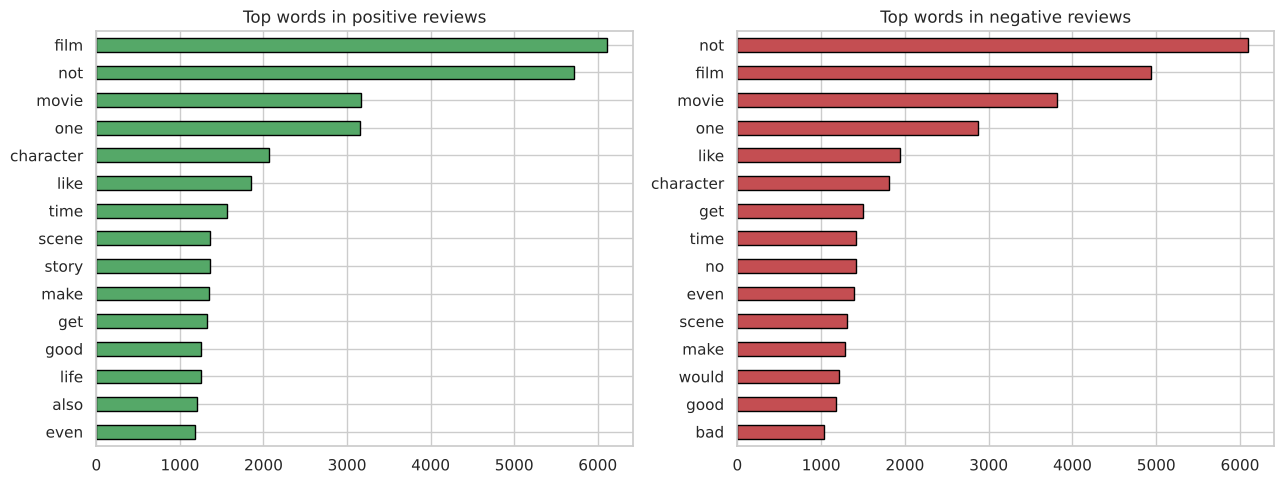

In [6]:
# Most frequent words in each class after cleaning
def top_words(label, n=15):
    c = Counter(" ".join(df.loc[df["label"] == label, "clean"]).split())
    return pd.Series(dict(c.most_common(n)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_words(1).sort_values().plot(kind="barh", ax=axes[0], color="#55a868", edgecolor="black")
axes[0].set_title("Top words in positive reviews")
top_words(0).sort_values().plot(kind="barh", ax=axes[1], color="#c44e52", edgecolor="black")
axes[1].set_title("Top words in negative reviews")
plt.tight_layout(); plt.show()

The most common words (*film*, *movie*, *one*) appear in both classes, which is exactly why **TF-IDF** is used: it down-weights words that appear in many documents and gives more weight to distinctive ones.

## 4. Train/test split and TF-IDF

The split is **80/20 and stratified**. The `TfidfVectorizer` sits inside a `Pipeline`, so its vocabulary and IDF weights are learned from training data only (and from the training folds only during cross-validation), which avoids leakage.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.20, random_state=RANDOM_STATE, stratify=df["label"])
print(f"Train: {len(X_train)} reviews | Test: {len(X_test)} reviews")

# Peek at what TF-IDF produces
peek = TfidfVectorizer(max_features=5000).fit(X_train)
M = peek.transform(X_train)
print(f"Feature matrix: {M.shape[0]} reviews x {M.shape[1]} features | sparsity: {1 - M.nnz / np.prod(M.shape):.1%}")

Train: 1600 reviews | Test: 400 reviews


Feature matrix: 1600 reviews x 5000 features | sparsity: 95.8%


## 5. Train and tune the models (5-fold cross-validation)

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(model):
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("clf", model)])

# Multinomial Naive Bayes: tune the smoothing parameter alpha
nb_grid = GridSearchCV(make_pipe(MultinomialNB()),
                       {"clf__alpha": [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0]},
                       cv=cv, scoring="accuracy", n_jobs=-1)
nb_grid.fit(X_train, y_train)

# Logistic Regression: tune the regularisation strength C
lr_grid = GridSearchCV(make_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
                       {"clf__C": [0.1, 0.5, 1, 3, 10, 30]},
                       cv=cv, scoring="accuracy", n_jobs=-1)
lr_grid.fit(X_train, y_train)

print(f"MultinomialNB       best alpha = {nb_grid.best_params_['clf__alpha']} | CV accuracy = {nb_grid.best_score_:.4f}")
print(f"LogisticRegression  best C     = {lr_grid.best_params_['clf__C']} | CV accuracy = {lr_grid.best_score_:.4f}")

MultinomialNB       best alpha = 0.5 | CV accuracy = 0.8025
LogisticRegression  best C     = 10 | CV accuracy = 0.8456


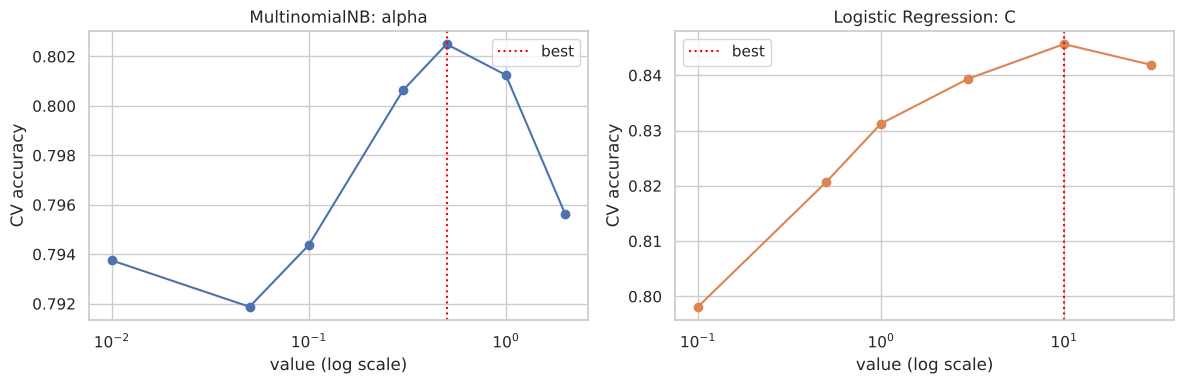

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grid, key, title, col in [(axes[0], nb_grid, "param_clf__alpha", "MultinomialNB: alpha", "#4c72b0"),
                                  (axes[1], lr_grid, "param_clf__C", "Logistic Regression: C", "#dd8452")]:
    p = grid.cv_results_[key].data.astype(float)
    ax.semilogx(p, grid.cv_results_["mean_test_score"], "o-", color=col)
    ax.axvline(grid.best_params_[list(grid.best_params_)[0]], color="red", ls=":", label="best")
    ax.set_title(title); ax.set_xlabel("value (log scale)"); ax.set_ylabel("CV accuracy"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Benchmark on the held-out test set

In [10]:
models = {"Multinomial Naive Bayes": nb_grid.best_estimator_, "Logistic Regression": lr_grid.best_estimator_}
cv_scores = {}

rows, preds, probas = [], {}, {}
for name, m in models.items():
    preds[name] = m.predict(X_test)
    probas[name] = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, preds[name]),
                 "Precision": precision_score(y_test, preds[name]),
                 "Recall": recall_score(y_test, preds[name]),
                 "F1": f1_score(y_test, preds[name]),
                 "ROC-AUC": roc_auc_score(y_test, probas[name])})
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Multinomial Naive Bayes,0.8125,0.8571,0.75,0.8000,0.8834
Logistic Regression,0.8475,0.8458,0.85,0.8479,0.9253


In [11]:
for name in models:
    print("=" * 55); print(name); print("=" * 55)
    print(classification_report(y_test, preds[name], target_names=["negative", "positive"], digits=3))

Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative      0.778     0.875     0.824       200
    positive      0.857     0.750     0.800       200

    accuracy                          0.812       400
   macro avg      0.817     0.812     0.812       400
weighted avg      0.817     0.812     0.812       400

Logistic Regression
              precision    recall  f1-score   support

    negative      0.849     0.845     0.847       200
    positive      0.846     0.850     0.848       200

    accuracy                          0.848       400
   macro avg      0.848     0.847     0.847       400
weighted avg      0.848     0.848     0.847       400



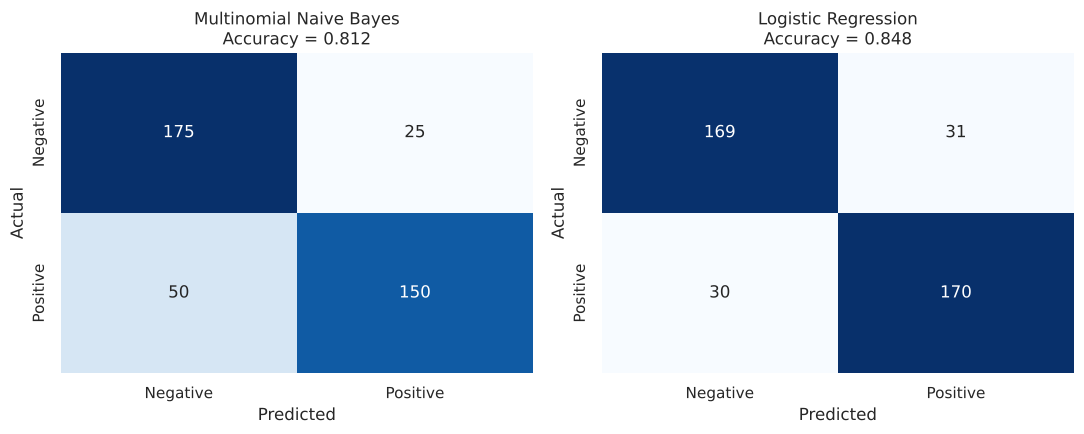

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, preds[name]):.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 7. Which words drive the predictions?

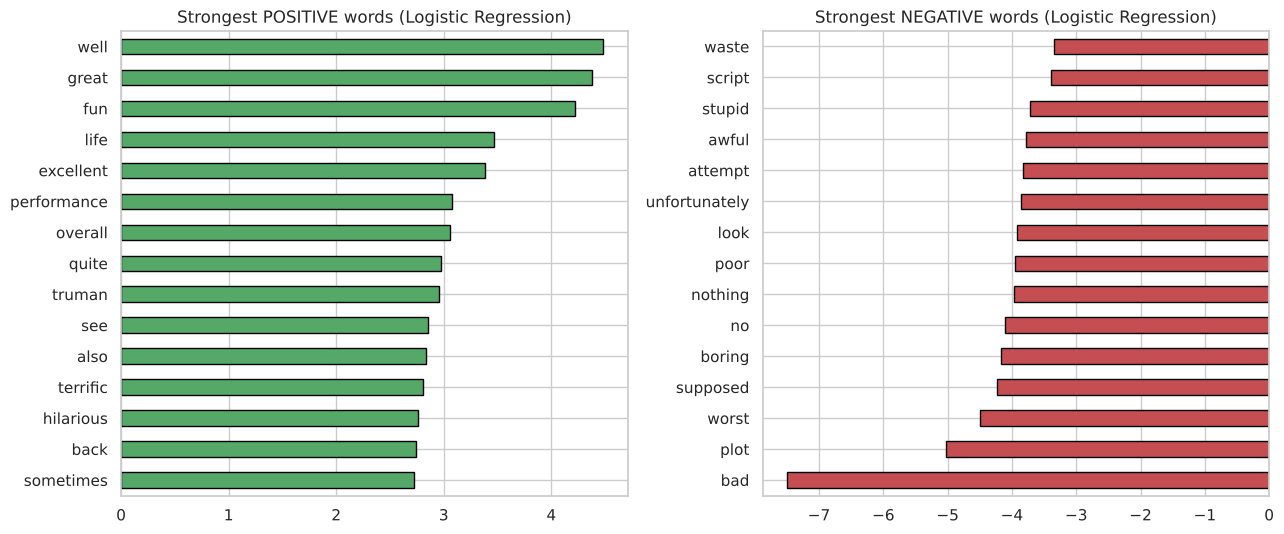

In [13]:
lr = models["Logistic Regression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_[0]
order = np.argsort(coef)

top_neg = pd.Series(coef[order[:15]], index=vocab[order[:15]])
top_pos = pd.Series(coef[order[-15:]], index=vocab[order[-15:]])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
top_pos.plot(kind="barh", ax=axes[0], color="#55a868", edgecolor="black")
axes[0].set_title("Strongest POSITIVE words (Logistic Regression)")
top_neg.plot(kind="barh", ax=axes[1], color="#c44e52", edgecolor="black")
axes[1].set_title("Strongest NEGATIVE words (Logistic Regression)")
plt.tight_layout(); plt.show()

## 8. Extension: can bigrams fix negation?

A unigram model sees "not good" as two unrelated words. Adding **bigrams** (`ngram_range=(1, 2)`) lets the vectorizer treat "not good" or "waste time" as features in their own right. The `max_features=5000` cap is kept, so this is a like-for-like comparison.

In [14]:
ext_specs = {
    "NB + bigrams": (MultinomialNB(), {"clf__alpha": [0.05, 0.1, 0.3, 0.5, 1.0]}),
    "LR + bigrams": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), {"clf__C": [1, 3, 10, 30]}),
}
for name, (clf, grid) in ext_specs.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))), ("clf", clf)])
    g = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
    models[name] = g.best_estimator_
    cv_scores[name] = g.best_score_

baseline_cv = {"Multinomial Naive Bayes": nb_grid.best_score_, "Logistic Regression": lr_grid.best_score_}
cv_scores.update(baseline_cv)

comparison = pd.DataFrame({
    "CV accuracy": {n: cv_scores[n] for n in models},
    "Test accuracy": {n: accuracy_score(y_test, m.predict(X_test)) for n, m in models.items()},
    "Test F1": {n: f1_score(y_test, m.predict(X_test)) for n, m in models.items()},
    "Test ROC-AUC": {n: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for n, m in models.items()},
}).round(4)
comparison

,CV accuracy,Test accuracy,Test F1,Test ROC-AUC
Multinomial Naive Bayes,0.8025,0.8125,0.8000,0.8834
Logistic Regression,0.8456,0.8475,0.8479,0.9253
NB + bigrams,0.8138,0.8025,0.7927,0.8868
LR + bigrams,0.8494,0.8625,0.8622,0.9275


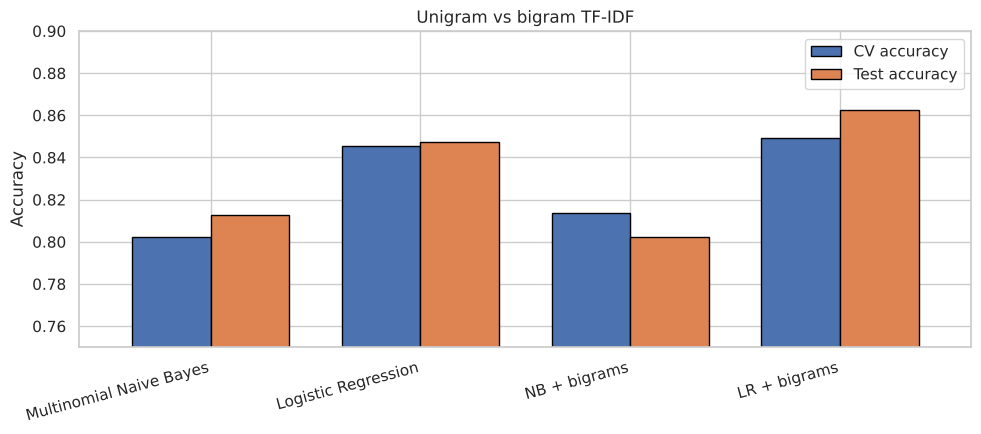

In [15]:
ax = comparison[["CV accuracy", "Test accuracy"]].plot(kind="bar", figsize=(10, 4.5), edgecolor="black", width=0.75)
ax.set_ylim(0.75, 0.90); ax.set_ylabel("Accuracy"); ax.set_title("Unigram vs bigram TF-IDF")
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

**Reading the result:** the cross-validated scores are the more reliable guide. With only 400 test reviews, one extra correct review moves test accuracy by 0.25 points, so small test differences are noise. Bigrams help a little, and they fix some negated phrases, but they cannot solve negation in general.

## 9. Live sentiment prediction

`predict_sentiment()` applies the **same cleaning** used in training, then runs the text through the fitted TF-IDF + classifier pipeline and returns the label with a confidence score.

In [16]:
def predict_sentiment(text, model="Logistic Regression", show=True):
    """Classify a piece of text as positive or negative.

    model: any key of `models`, e.g. "Logistic Regression", "Multinomial Naive Bayes", "LR + bigrams"
    Returns (label, confidence).
    """
    pipe = models[model]
    cleaned = clean_text(text)
    if not cleaned.strip():
        if show: print(f"'{text}' -> no usable words after cleaning")
        return None, None
    proba = pipe.predict_proba([cleaned])[0]            # [P(negative), P(positive)]
    label = "positive" if proba[1] >= 0.5 else "negative"
    conf = max(proba)
    if show:
        print(f"{label.upper():8s} ({conf:.0%} confidence)  <-  {text}")
    return label, conf

predict_sentiment("This movie was absolutely wonderful, I loved every minute of it!")
predict_sentiment("Terrible film. Boring plot and awful acting, a complete waste of time.")

POSITIVE (71% confidence)  <-  This movie was absolutely wonderful, I loved every minute of it!
NEGATIVE (100% confidence)  <-  Terrible film. Boring plot and awful acting, a complete waste of time.


('negative', np.float64(0.9993147061484162))

In [17]:
test_phrases = [
    "An outstanding performance with a brilliant, moving story.",
    "I would not recommend this to anyone. It was dull and badly written.",
    "The film was not good at all.",
    "Not bad, actually quite enjoyable.",
    "A masterpiece of modern cinema.",
    "The plot made no sense and the characters were flat.",
    "Great cast, stunning visuals, and a satisfying ending.",
    "I fell asleep halfway through.",
]

for name in models:
    print(f"\n--- {name} ---")
    for t in test_phrases: predict_sentiment(t, name)


--- Multinomial Naive Bayes ---
POSITIVE (84% confidence)  <-  An outstanding performance with a brilliant, moving story.
NEGATIVE (77% confidence)  <-  I would not recommend this to anyone. It was dull and badly written.
NEGATIVE (52% confidence)  <-  The film was not good at all.
NEGATIVE (51% confidence)  <-  Not bad, actually quite enjoyable.
POSITIVE (68% confidence)  <-  A masterpiece of modern cinema.
NEGATIVE (68% confidence)  <-  The plot made no sense and the characters were flat.
POSITIVE (79% confidence)  <-  Great cast, stunning visuals, and a satisfying ending.
NEGATIVE (70% confidence)  <-  I fell asleep halfway through.

--- Logistic Regression ---
POSITIVE (97% confidence)  <-  An outstanding performance with a brilliant, moving story.
NEGATIVE (92% confidence)  <-  I would not recommend this to anyone. It was dull and badly written.
POSITIVE (69% confidence)  <-  The film was not good at all.
NEGATIVE (65% confidence)  <-  Not bad, actually quite enjoyable.
POSITIVE 

In [18]:
def interactive_test():
    """Type your own reviews and see the prediction. Enter 'q' to stop."""
    while True:
        text = input("Enter a review (or 'q' to quit): ")
        if text.strip().lower() in {"q", "quit", "exit"}:
            print("Done."); break
        predict_sentiment(text)

# Uncomment the next line and run this cell to test your own phrases interactively:
# interactive_test()

**Try it yourself:** uncomment `interactive_test()` above and run the cell. A text box appears at the top of VS Code for each phrase you want to test.

## 10. Conclusion

- **Baseline results:** with TF-IDF (5,000 features) Logistic Regression reaches **84.8% test accuracy** (ROC-AUC 0.925) and Multinomial Naive Bayes reaches **81.3%** (ROC-AUC 0.883). Cross-validation agrees (84.6% vs 80.3%), so Logistic Regression is the stronger model on this dataset. Naive Bayes is faster and simpler but misses more positive reviews (recall 0.75 vs 0.85).
- **Bigrams help only a little.** Adding word pairs raised Logistic Regression to 84.9% cross-validated and 86.3% test accuracy. For Naive Bayes the cross-validated score rose slightly while the test score fell, so the differences are within the noise of a 400-review test set.
- **Live testing shows the main weakness.** All four models handle clearly worded reviews well ("outstanding performance", "plot made no sense"). But "Not bad, actually quite enjoyable" is misclassified by **every** model, and "The film was not good at all" is misclassified by the unigram Logistic Regression. Bag-of-words models ignore word order, so negation and sarcasm are hard for them. Keeping negation words out of the stopword list helps, but does not solve it.
- **Limitations:** the dataset has only 2,000 reviews, all about movies, so the models will transfer poorly to product reviews or other domains. Training reviews average about 750 words, so confidence on short phrases is lower and less reliable.
- **Next steps:** train on a larger corpus (such as the 50,000-review IMDB dataset), try a linear SVM, or move to pretrained transformer embeddings, which handle negation and context far better.